In [1]:
import scanpy as sc
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

In [2]:
adata = sc.read_h5ad('/local/hailey/PLX/combined_data_process.h5ad')
meta = pd.read_csv('/local/hailey/PLX/combined_data_process_meta_allenmap.csv', index_col=0)
adata.obs = meta  #cell annotation --- 'anno_0825' column

In [ ]:
#Cellbin Process Steps; no need to run again
# Calculate QC metrics
sc.pp.calculate_qc_metrics(combined_data, percent_top=None, log1p=False, inplace=True)
#Filtering
adata = adata[
    (adata.obs["nFeature_Spatial"] >= 200) &
    (adata.obs["nCount_Spatial"] >= 300) &
    (adata.obs["percent.mito"] <= 15),
].copy()
adata

# Normalize the expression matrix to 10k reads per cell
sc.pp.normalize_total(combined_data, target_sum=1e4)

# Logarithmize the data
sc.pp.log1p(combined_data)

# Save the raw data
combined_data.raw = combined_data

# Find highly variable genes
sc.pp.highly_variable_genes(combined_data, min_mean=0.0125, max_mean=3, min_disp=0.5,n_top_genes=3000)
sc.pl.highly_variable_genes(combined_data)

combined_data = combined_data[:, combined_data.var.highly_variable]
sc.pp.scale(combined_data, max_value=10)

sc.tl.pca(combined_data, svd_solver='arpack')
# Compute the neighborhood graph
sc.pp.neighbors(combined_data, use_rep='X_pca_harmony')
sc.tl.umap(combined_data)

In [4]:
adata

AnnData object with n_obs × n_vars = 2381759 × 3000
    obs: 'dnbCount', 'area', 'nCount_Spatial', 'nFeature_Spatial', 'percent.mito', 'orig.ident', 'x', 'y', 'Sample', 'ChipID', 'Tissue', 'MouseID', 'Group', 'Sex', 'SlicingDate', 'batch', 'clusters', 'predicted_labels', 'over_clustering', 'majority_voting', 'conf_score', 'cell_id', 'class_label', 'class_name', 'class_bootstrapping_probability', 'subclass_label', 'subclass_name', 'subclass_bootstrapping_probability', 'supertype_label', 'supertype_name', 'supertype_bootstrapping_probability', 'cluster_label', 'cluster_name', 'cluster_alias', 'cluster_bootstrapping_probability', 'name', 'Group1', 'anno_01', 'anno_02', 'anno_03', 'class_name_group', 'Sex_group', 'Sex_group1', 'anno_new', 'anno_new_class', 'new_class', 'Anno_Clusters', 'anno_0825'
    var: 'ENSid-0', 'n_cells-0', 'n_counts-0', 'mean_umi-0', 'ENSid-1', 'n_cells-1', 'n_counts-1', 'mean_umi-1', 'ENSid-10', 'n_cells-10', 'n_counts-10', 'mean_umi-10', 'ENSid-11', 'n_cells-11', 

<Figure size 700x400 with 0 Axes>

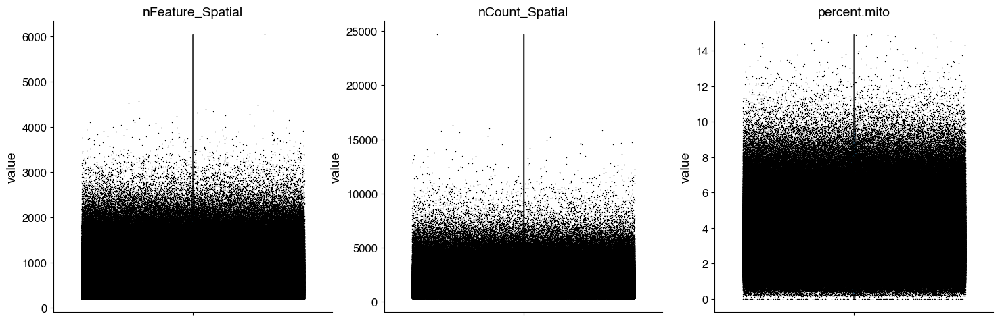

In [5]:
plt.figure(figsize=(7, 4))  
# Helvetica
plt.rcParams["font.family"] = "sans-serif"
plt.rcParams["font.sans-serif"] = ["Helvetica"]  
plt.rcParams["pdf.fonttype"] = 42
plt.rcParams["ps.fonttype"] = 42
with plt.rc_context({
    "font.size": 14,
    "axes.titlesize": 16,
    "axes.labelsize": 14,
    "xtick.labelsize": 12,
    "ytick.labelsize": 12,
}):
    sc.pl.violin(
        adata,
        ["nFeature_Spatial", "nCount_Spatial", "percent.mito"],
        jitter=0.4,
        multi_panel=True,
        save="QC.png",
    )

/home/hailey/conda/envs/st/lib/python3.8/site-packages/scanpy/plotting/_dotplot.py:747: UserWarning: No data for colormapping provided via 'c'. Parameters 'cmap', 'norm' will be ignored
  dot_ax.scatter(x, y, **kwds)


webf NOT subset; don't know how to subset; dropped


<Figure size 640x480 with 0 Axes>

<Figure size 700x600 with 0 Axes>

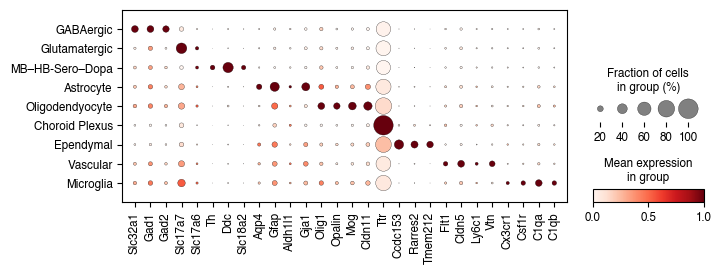

In [6]:
#figure 1B
import matplotlib.pyplot as plt
import scanpy as sc
# 设置图形参数
plt.subplots_adjust(bottom=0.1, top=0.9)

adata.obs['anno_0825'] = adata.obs['anno_0825'].astype('category')
pop=['GABAergic','Glutamatergic','MB–HB-Sero–Dopa','Astrocyte','Oligodendyocyte','Choroid Plexus','Ependymal',
     'Vascular','Microglia'
    ]
adata.obs['anno_0825']= adata.obs['anno_0825'].cat.reorder_categories(pop)

marker_genes_list = [
    "Slc32a1", "Gad1", "Gad2","Slc17a7","Slc17a6",#"Slc6a13",
    "Th","Ddc","Slc18a2",#"Htr1a",
    "Aqp4","Gfap","Aldh1l1","Gja1","Olig1",#"Olig2",
    "Opalin",
    "Mog","Cldn11",#"Pdgfra","Vcan",
    "Ttr","Ccdc153", "Rarres2", "Tmem212","Flt1", "Cldn5",
    "Ly6c1","Vtn",#"Ifitm1","Acta2","Slc6a13",
    "Cx3cr1", "Csf1r", "C1qa", "C1qb"#,"Spp1"
]

plt.figure(figsize=(7, 6))  
#figsize=(10, 4)
sc.pl.dotplot(adata, marker_genes_list, groupby="anno_0825", save = 'anno_0825',
              standard_scale="var",figsize=(7.5, 2.5))

/tmp/ipykernel_3859461/3887999940.py:21: ImplicitModificationWarning: Trying to modify attribute `.obs` of view, initializing view as actual.
  adata_sample.obs['anno_0825'] = adata_sample.obs['anno_0825'].astype('category')


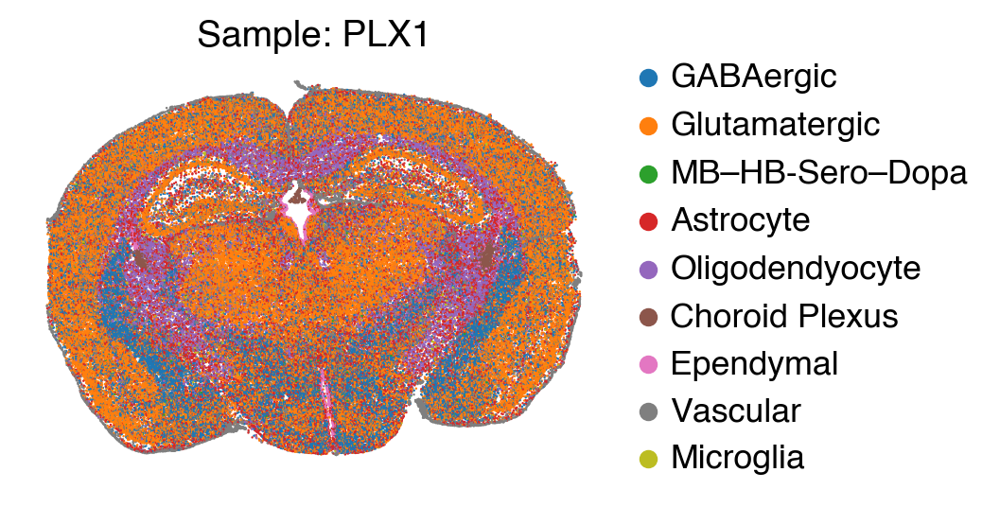

/tmp/ipykernel_3859461/3887999940.py:21: ImplicitModificationWarning: Trying to modify attribute `.obs` of view, initializing view as actual.
  adata_sample.obs['anno_0825'] = adata_sample.obs['anno_0825'].astype('category')


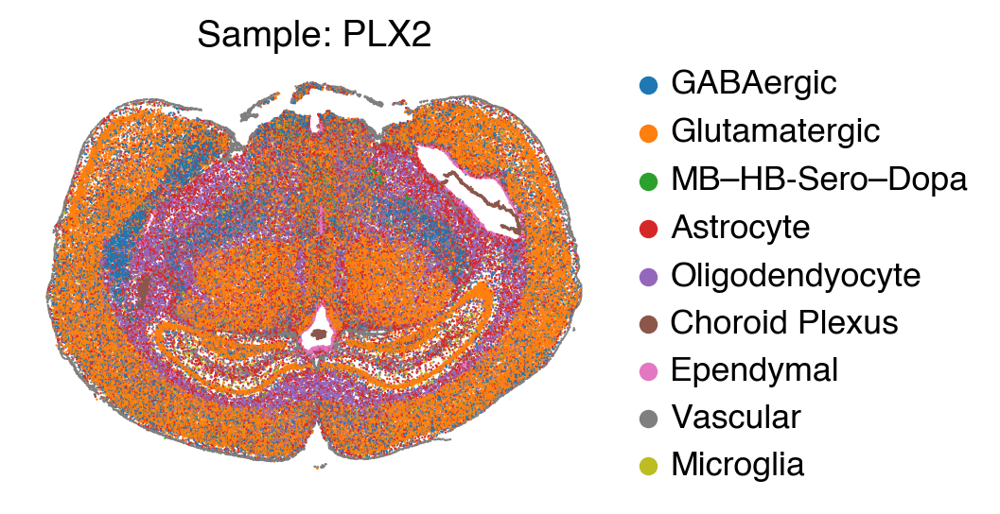

/tmp/ipykernel_3859461/3887999940.py:21: ImplicitModificationWarning: Trying to modify attribute `.obs` of view, initializing view as actual.
  adata_sample.obs['anno_0825'] = adata_sample.obs['anno_0825'].astype('category')


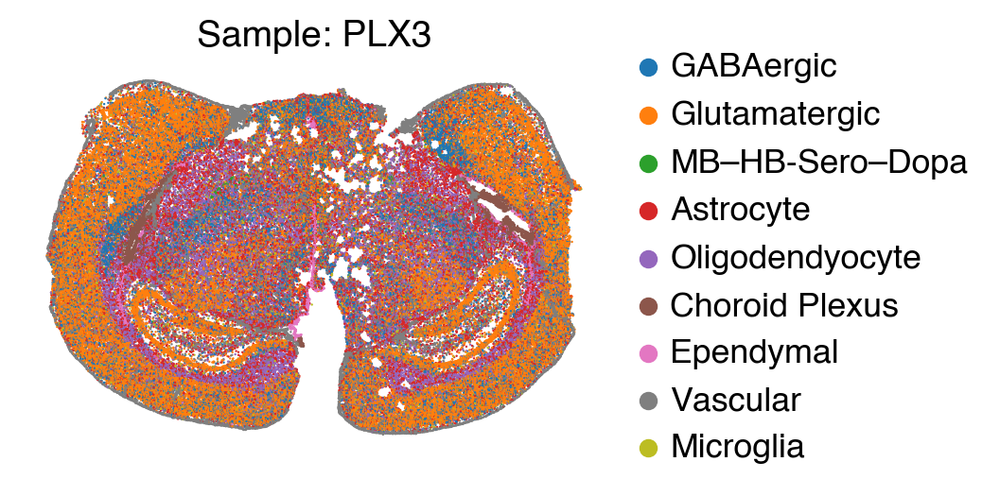

/tmp/ipykernel_3859461/3887999940.py:21: ImplicitModificationWarning: Trying to modify attribute `.obs` of view, initializing view as actual.
  adata_sample.obs['anno_0825'] = adata_sample.obs['anno_0825'].astype('category')


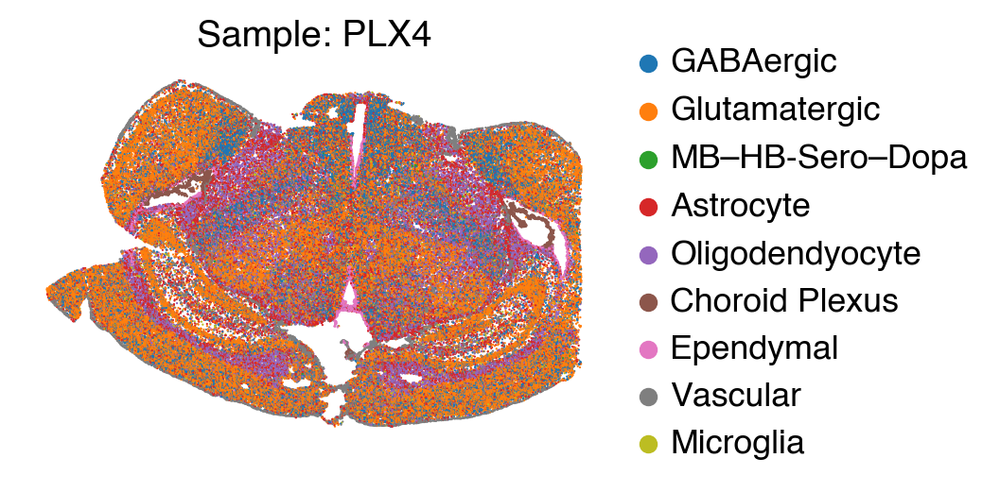

/tmp/ipykernel_3859461/3887999940.py:21: ImplicitModificationWarning: Trying to modify attribute `.obs` of view, initializing view as actual.
  adata_sample.obs['anno_0825'] = adata_sample.obs['anno_0825'].astype('category')


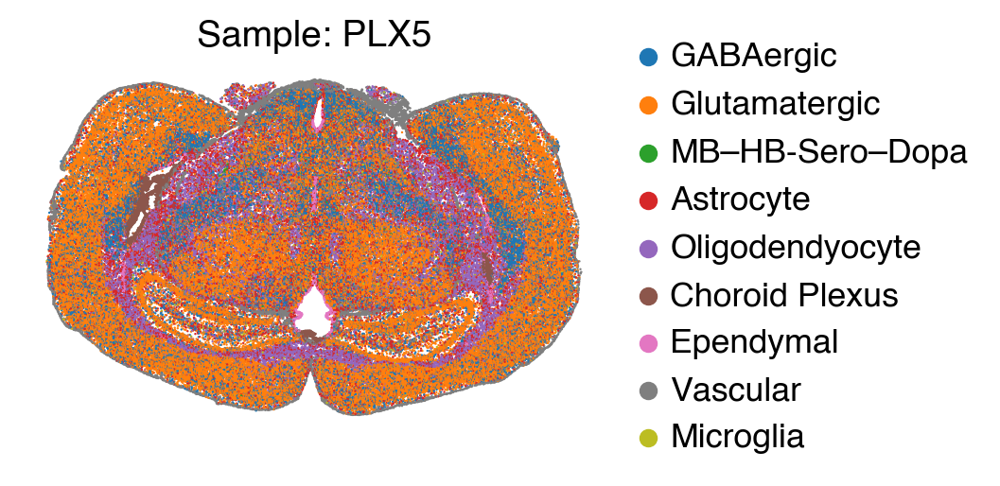

/tmp/ipykernel_3859461/3887999940.py:21: ImplicitModificationWarning: Trying to modify attribute `.obs` of view, initializing view as actual.
  adata_sample.obs['anno_0825'] = adata_sample.obs['anno_0825'].astype('category')


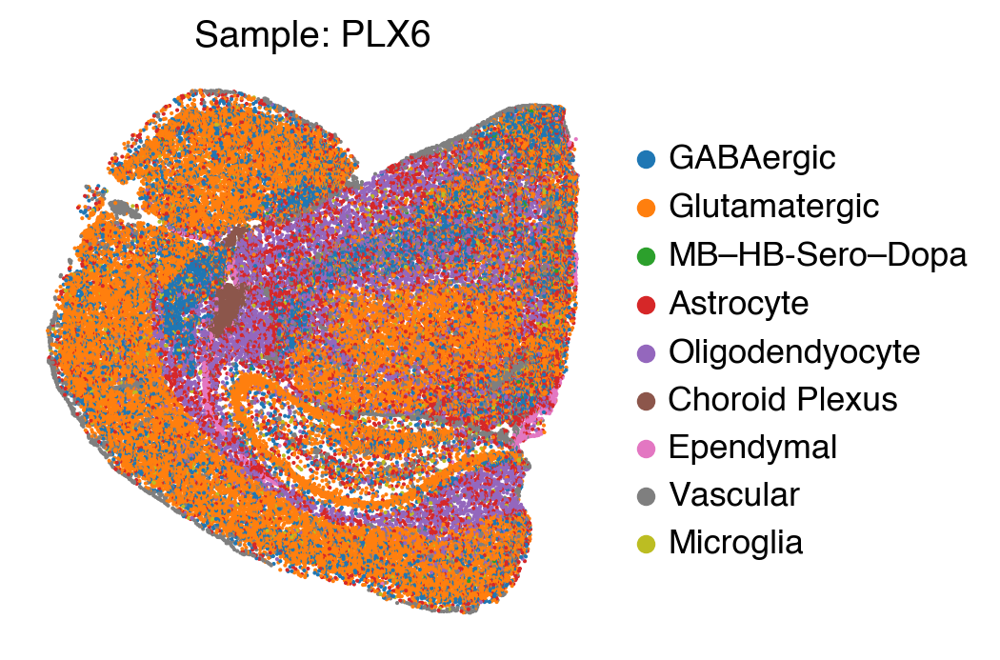

/tmp/ipykernel_3859461/3887999940.py:21: ImplicitModificationWarning: Trying to modify attribute `.obs` of view, initializing view as actual.
  adata_sample.obs['anno_0825'] = adata_sample.obs['anno_0825'].astype('category')


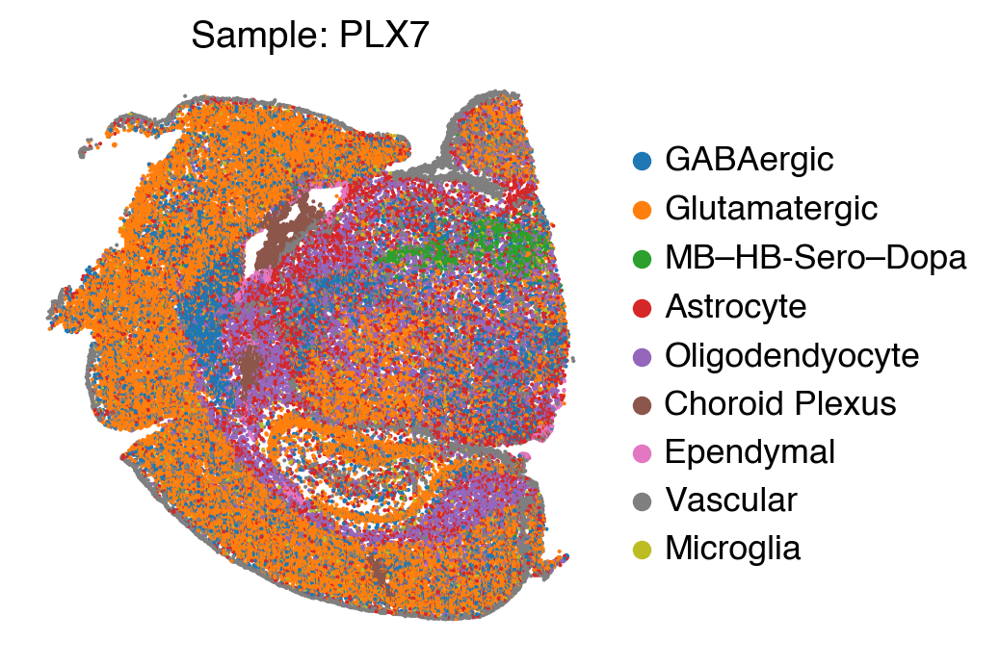

/tmp/ipykernel_3859461/3887999940.py:21: ImplicitModificationWarning: Trying to modify attribute `.obs` of view, initializing view as actual.
  adata_sample.obs['anno_0825'] = adata_sample.obs['anno_0825'].astype('category')


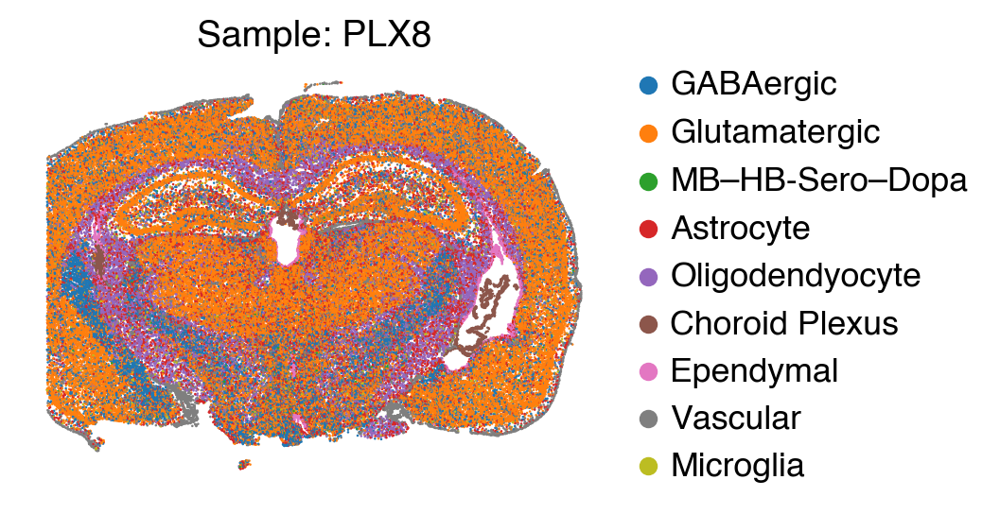

/tmp/ipykernel_3859461/3887999940.py:21: ImplicitModificationWarning: Trying to modify attribute `.obs` of view, initializing view as actual.
  adata_sample.obs['anno_0825'] = adata_sample.obs['anno_0825'].astype('category')


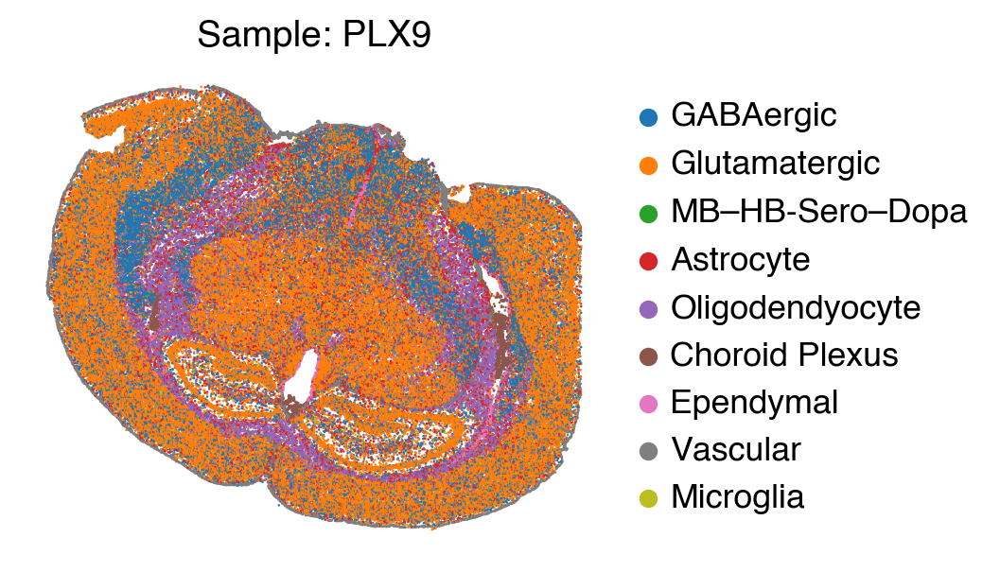

/tmp/ipykernel_3859461/3887999940.py:21: ImplicitModificationWarning: Trying to modify attribute `.obs` of view, initializing view as actual.
  adata_sample.obs['anno_0825'] = adata_sample.obs['anno_0825'].astype('category')


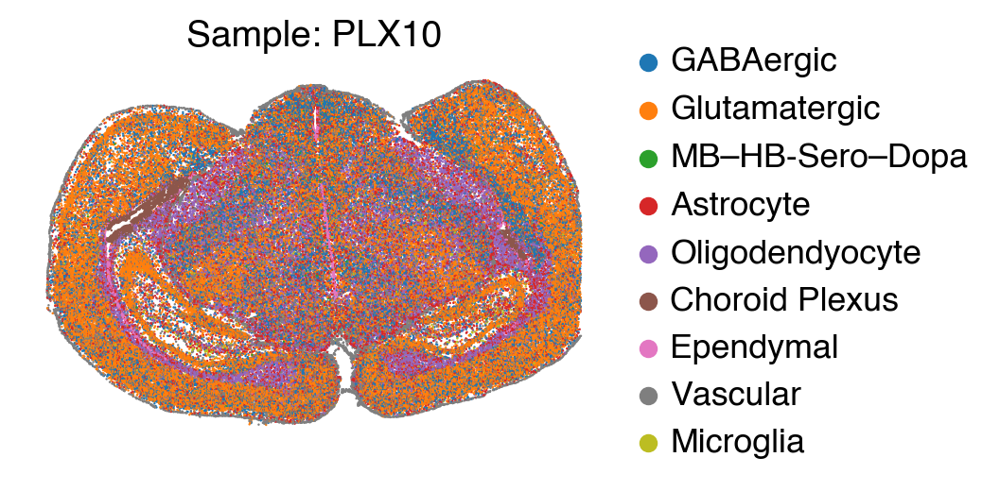

/tmp/ipykernel_3859461/3887999940.py:21: ImplicitModificationWarning: Trying to modify attribute `.obs` of view, initializing view as actual.
  adata_sample.obs['anno_0825'] = adata_sample.obs['anno_0825'].astype('category')


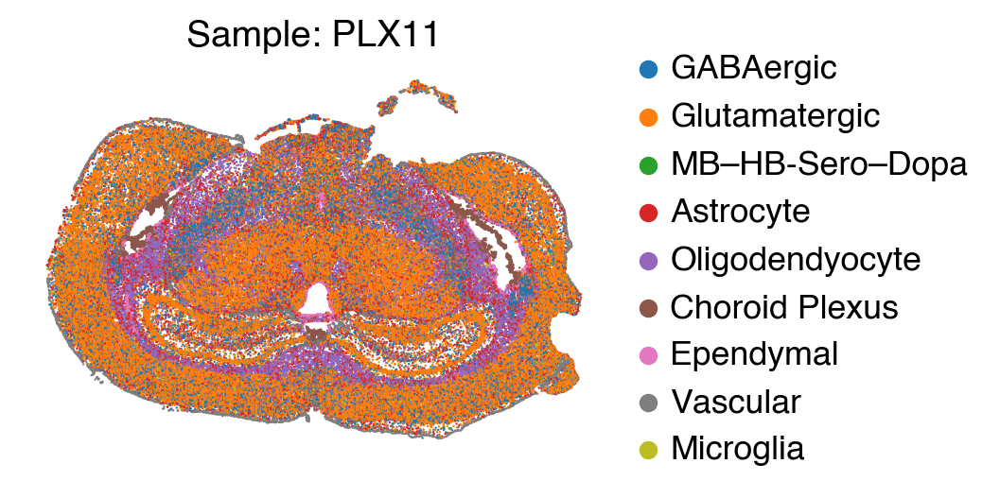

/tmp/ipykernel_3859461/3887999940.py:21: ImplicitModificationWarning: Trying to modify attribute `.obs` of view, initializing view as actual.
  adata_sample.obs['anno_0825'] = adata_sample.obs['anno_0825'].astype('category')


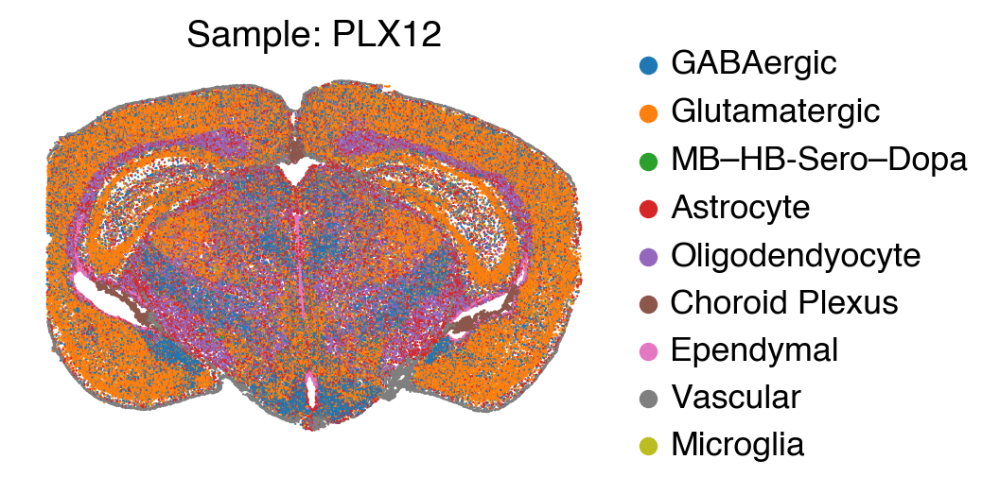

/tmp/ipykernel_3859461/3887999940.py:21: ImplicitModificationWarning: Trying to modify attribute `.obs` of view, initializing view as actual.
  adata_sample.obs['anno_0825'] = adata_sample.obs['anno_0825'].astype('category')


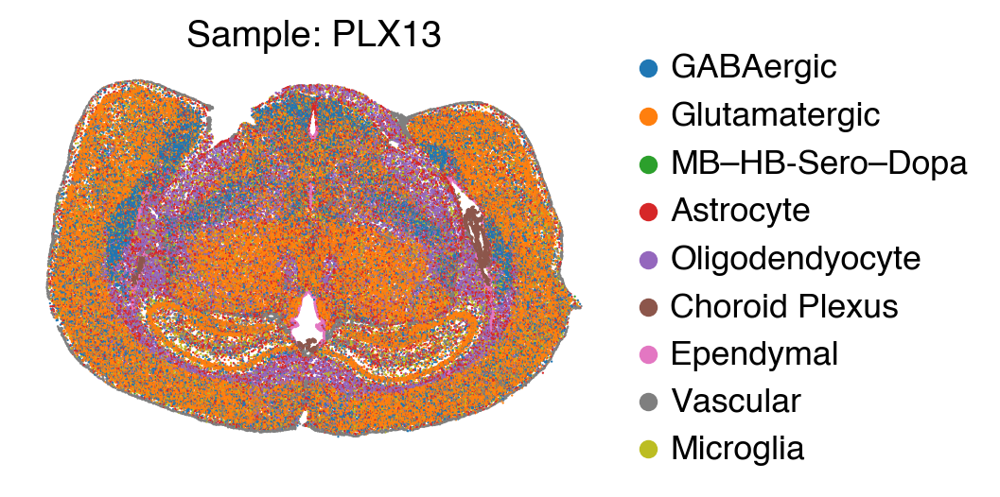

/tmp/ipykernel_3859461/3887999940.py:21: ImplicitModificationWarning: Trying to modify attribute `.obs` of view, initializing view as actual.
  adata_sample.obs['anno_0825'] = adata_sample.obs['anno_0825'].astype('category')


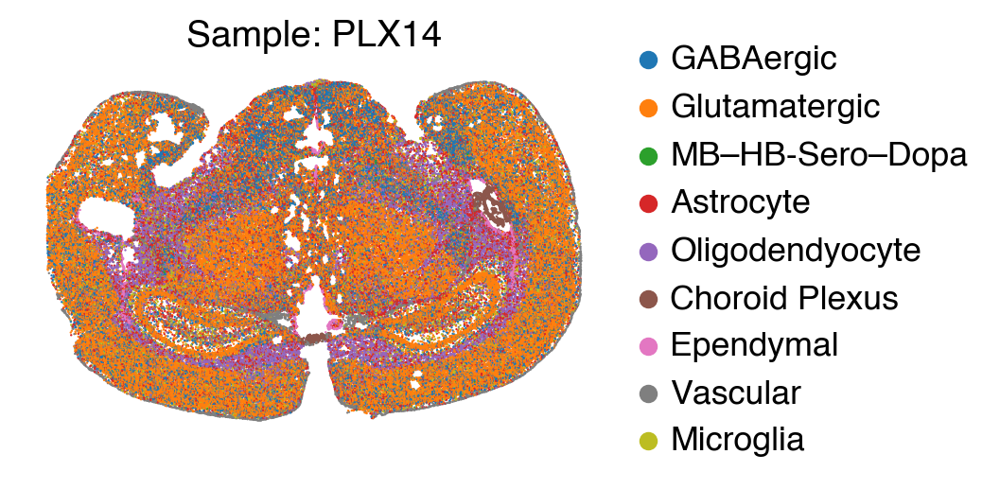

/tmp/ipykernel_3859461/3887999940.py:21: ImplicitModificationWarning: Trying to modify attribute `.obs` of view, initializing view as actual.
  adata_sample.obs['anno_0825'] = adata_sample.obs['anno_0825'].astype('category')


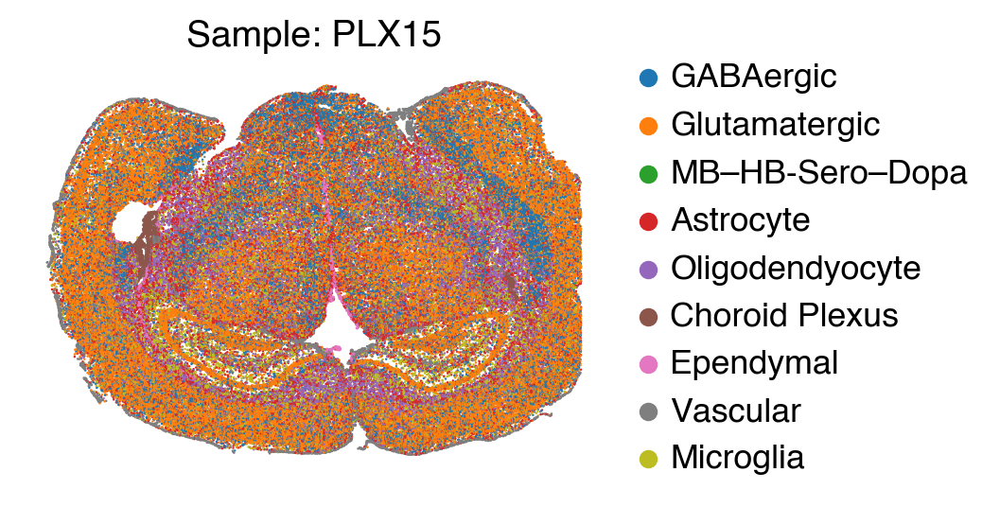

/tmp/ipykernel_3859461/3887999940.py:21: ImplicitModificationWarning: Trying to modify attribute `.obs` of view, initializing view as actual.
  adata_sample.obs['anno_0825'] = adata_sample.obs['anno_0825'].astype('category')


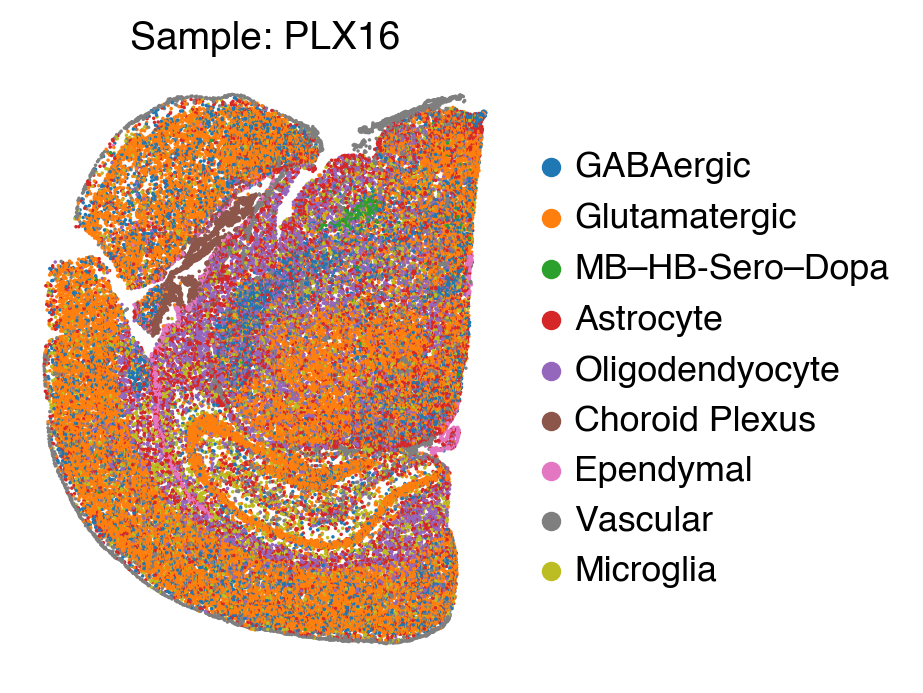

/tmp/ipykernel_3859461/3887999940.py:21: ImplicitModificationWarning: Trying to modify attribute `.obs` of view, initializing view as actual.
  adata_sample.obs['anno_0825'] = adata_sample.obs['anno_0825'].astype('category')


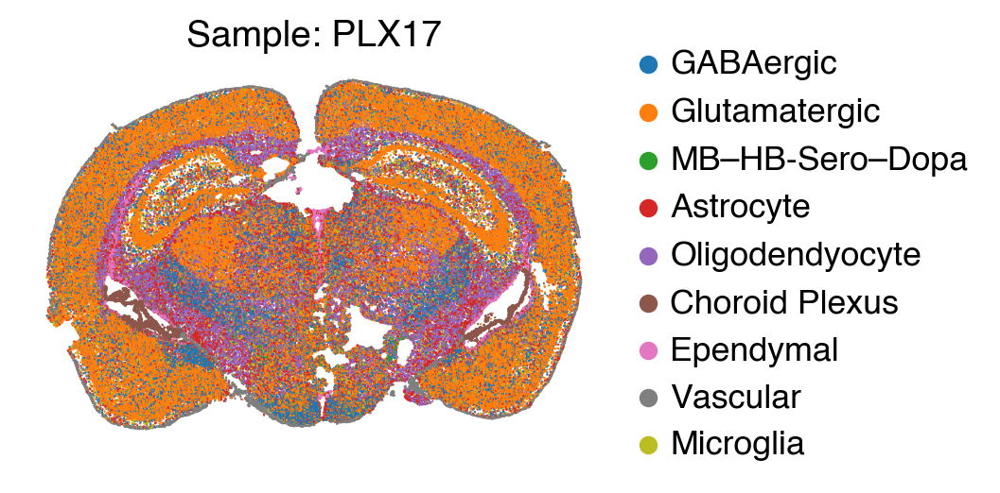

/tmp/ipykernel_3859461/3887999940.py:21: ImplicitModificationWarning: Trying to modify attribute `.obs` of view, initializing view as actual.
  adata_sample.obs['anno_0825'] = adata_sample.obs['anno_0825'].astype('category')


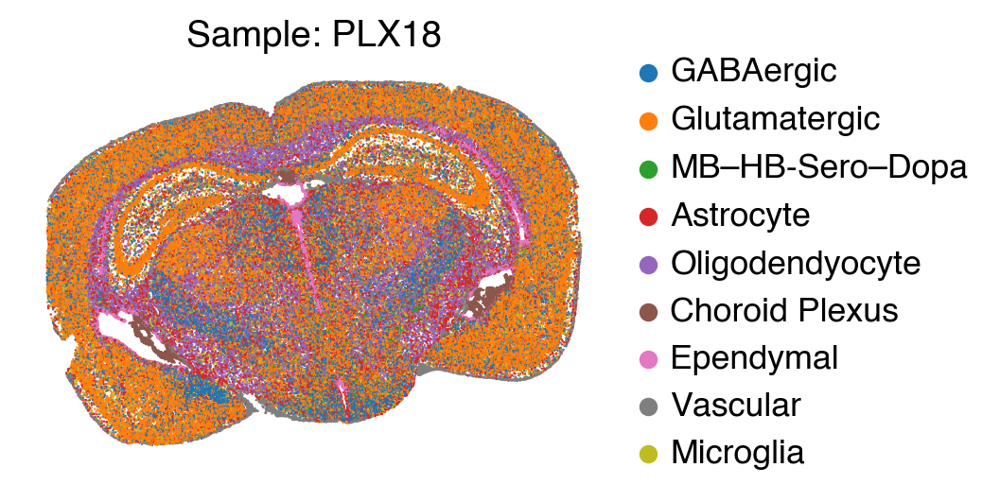

/tmp/ipykernel_3859461/3887999940.py:21: ImplicitModificationWarning: Trying to modify attribute `.obs` of view, initializing view as actual.
  adata_sample.obs['anno_0825'] = adata_sample.obs['anno_0825'].astype('category')


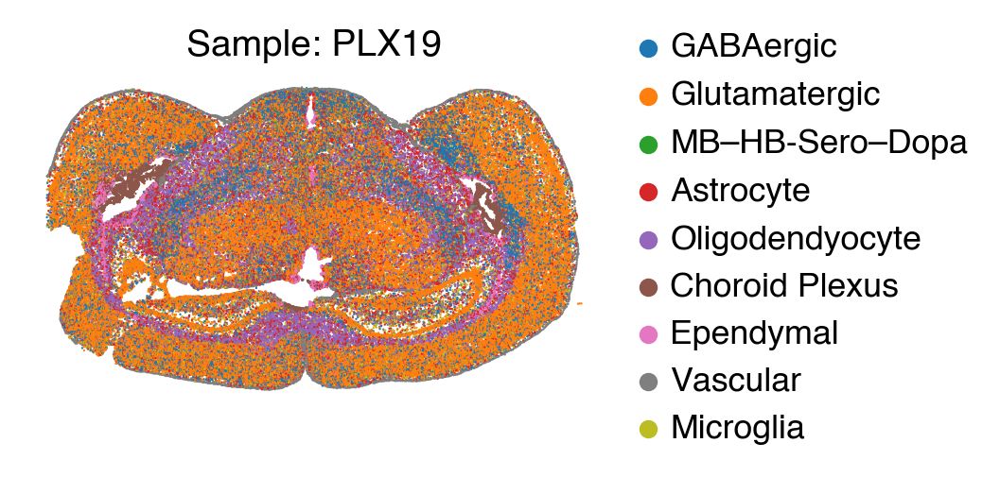

/tmp/ipykernel_3859461/3887999940.py:21: ImplicitModificationWarning: Trying to modify attribute `.obs` of view, initializing view as actual.
  adata_sample.obs['anno_0825'] = adata_sample.obs['anno_0825'].astype('category')


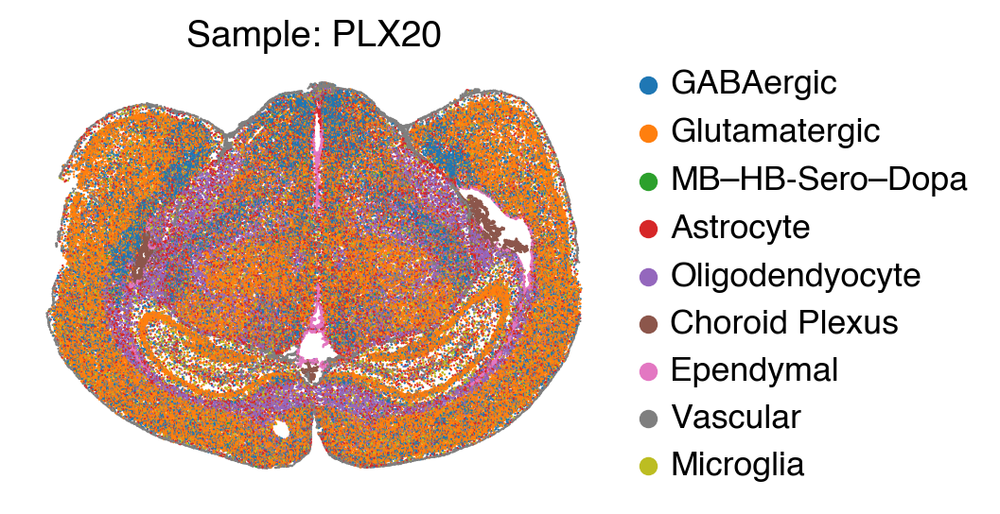

In [6]:
#figure 1E
palette={
    'GABAergic' : '#1f77b4',
    'Glutamatergic' :  '#ff7f0e',
    'MB–HB-Sero–Dopa' :  '#2ca02c',
    'Astrocyte' :  '#d62728',
    'Oligodendyocyte' :  '#9467bd',
    'Choroid Plexus' :  '#8c564b',
    'Ependymal' :  '#e377c2',
     'Vascular' : '#7f7f7f',
    'Microglia' :  '#bcbd22'
}

samples = adata.obs['Sample'].unique()
sc.settings.set_figure_params(dpi=100, dpi_save=400,
                              frameon=False, transparent=True)


for sample in samples:
    adata_sample = adata[adata.obs['Sample'] == sample]
    adata_sample.obs['anno_0825'] = adata_sample.obs['anno_0825'].astype('category')
    pop=['GABAergic','Glutamatergic','MB–HB-Sero–Dopa','Astrocyte','Oligodendyocyte','Choroid Plexus','Ependymal',
     'Vascular','Microglia'
    ]
    adata_sample.obs['anno_0825']= adata_sample.obs['anno_0825'].cat.reorder_categories(pop)
    
    sc.pl.spatial(
        adata_sample, 
        img_key="hires", 
        color="anno_0825", palette = palette,
        spot_size=80, 
        title=f'Sample: {sample}', 
        save=f'_{sample}_anno_0825.png'  
    )